In [1]:
# Cell 1: Import necessary libraries
import os
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from torch.cuda.amp import GradScaler, autocast
from tqdm import tqdm
import gc

In [3]:
# Cell 2: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Cell 3: Unzip the images zip file from Drive to Colab
# Assume the zip is at /content/drive/MyDrive/book_images_small.zip
# Unzip to /content/book_images_small
!unzip /content/drive/MyDrive/book_images_small.zip -d /content/book_images_small
img_dir = '/content/book_images_small/book_images_small'  # Adjust if unzip creates subfolder, e.g., '/content/book_images_small/book_images_small' if nested

Streaming output truncated to the last 5000 lines.
  inflating: /content/book_images_small/book_images_small/61sADBuaZkL.jpg  
  inflating: /content/book_images_small/book_images_small/61SAe9m7BhL.jpg  
  inflating: /content/book_images_small/book_images_small/61sagbMTNOL.jpg  
  inflating: /content/book_images_small/book_images_small/61sakGWRvOL.jpg  
  inflating: /content/book_images_small/book_images_small/61salSdLN8L.jpg  
  inflating: /content/book_images_small/book_images_small/61samjLiRCL.jpg  
  inflating: /content/book_images_small/book_images_small/61SAmvPU3RL.jpg  
  inflating: /content/book_images_small/book_images_small/61SAN12re0L.jpg  
  inflating: /content/book_images_small/book_images_small/61saNe0ip3L.jpg  
  inflating: /content/book_images_small/book_images_small/61SAnFNvvXL.jpg  
  inflating: /content/book_images_small/book_images_small/61saorcNFJL.jpg  
  inflating: /content/book_images_small/book_images_small/61SapUJI3zL.jpg  
  inflating: /content/book_images_sma

In [5]:
# Cell 4: Load CSV and preprocess
# Assume CSV is at /content/drive/MyDrive/book_list.csv
csv_path = '/content/drive/MyDrive/book_list.csv'
df = pd.read_csv(csv_path, encoding='latin-1')

# Extract filename from IMAGE URL
df['filename'] = df['IMAGE URL'].apply(lambda x: x.split('/')[-1])

# Get list of available images
available_images = set(os.listdir(img_dir))

# Filter rows where image exists
df = df[df['filename'].isin(available_images)].reset_index(drop=True)

# Get number of classes (assuming CATEGORY ID is the label, starting from 0)
num_classes = df['CATEGORY ID'].nunique()
print(f"Number of classes: {num_classes}")
print(f"Filtered dataset size: {len(df)}")

Number of classes: 32
Filtered dataset size: 207552


In [6]:
# Cell 5: Split the dataset
# 50% train, 20% val, 30% test (from original)
train_df, temp_df = train_test_split(df, test_size=0.5, stratify=df['CATEGORY ID'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.3, stratify=temp_df['CATEGORY ID'], random_state=42)  # 0.4 of 50% = 20% of original

print(f"Train size: {len(train_df)}")
print(f"Val size: {len(val_df)}")
print(f"Test size: {len(test_df)}")

Train size: 103776
Val size: 72643
Test size: 31133


In [7]:
# Cell 6: Define custom Dataset class
class BookDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, row['filename'])
        image = Image.open(img_path).convert('RGB')
        label = row['CATEGORY ID']  # Assuming CATEGORY ID is integer label starting from 0
        if self.transform:
            image = self.transform(image)
        return image, label

In [8]:
# Cell 7: Define transforms
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [9]:
# Cell 8: Create datasets and dataloaders
# Use batch size 128 to utilize GPU memory (adjust if OOM, e.g., to 64 for larger models)
batch_size = 128
num_workers = 4  # For faster data loading

train_ds = BookDataset(train_df, img_dir, train_transform)
val_ds = BookDataset(val_df, img_dir, val_transform)
test_ds = BookDataset(test_df, img_dir, val_transform)

train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
test_dl = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [10]:
# Cell 9: Define training and evaluation functions
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def train_epoch(model, dataloader, criterion, optimizer, scaler):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for inputs, labels in tqdm(dataloader):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        with autocast():
            outputs = model(inputs)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
    return total_loss / len(dataloader), correct / total

def evaluate(model, dataloader, criterion):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in tqdm(dataloader):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
    return total_loss / len(dataloader), correct / total

In [11]:
# Cell 10: Train EfficientNet model
# Use efficientnet_b4 for better accuracy, pre-trained
from torchvision.models import efficientnet_b4, EfficientNet_B4_Weights

model_eff = efficientnet_b4(weights=EfficientNet_B4_Weights.DEFAULT)
num_ftrs = model_eff.classifier[1].in_features
model_eff.classifier[1] = nn.Linear(num_ftrs, num_classes)
model_eff.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_eff = optim.AdamW(model_eff.parameters(), lr=1e-3)
scaler_eff = GradScaler()
scheduler_eff = optim.lr_scheduler.ReduceLROnPlateau(optimizer_eff, mode='min', factor=0.1, patience=3)

epochs = 15  # Increased epochs for better convergence to 60%+
best_acc = 0

for epoch in range(epochs):
    train_loss, train_acc = train_epoch(model_eff, train_dl, criterion, optimizer_eff, scaler_eff)
    val_loss, val_acc = evaluate(model_eff, val_dl, criterion)
    scheduler_eff.step(val_loss)
    print(f"Epoch {epoch+1}: Train Loss {train_loss:.4f}, Acc {train_acc:.4f} | Val Loss {val_loss:.4f}, Acc {val_acc:.4f}")
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model_eff.state_dict(), 'efficientnet_best.pth')
    gc.collect()
    torch.cuda.empty_cache()  # Clear cache to optimize GPU memory

# Evaluate on test
test_loss, test_acc = evaluate(model_eff, test_dl, criterion)
print(f"EfficientNet Test Acc: {test_acc:.4f}")

Downloading: "https://download.pytorch.org/models/efficientnet_b4_rwightman-23ab8bcd.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b4_rwightman-23ab8bcd.pth


100%|██████████| 74.5M/74.5M [00:00<00:00, 207MB/s]
/tmp/ipython-input-2838395992.py:12: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_eff = GradScaler()
  0%|          | 0/811 [00:00<?, ?it/s]/tmp/ipython-input-3720486319.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
100%|██████████| 568/568 [04:25<00:00,  2.14it/s]


Epoch 1: Train Loss 2.6534, Acc 0.2638 | Val Loss 2.3631, Acc 0.3369


100%|██████████| 568/568 [04:26<00:00,  2.13it/s]


Epoch 2: Train Loss 2.4158, Acc 0.3222 | Val Loss 2.2633, Acc 0.3604


100%|██████████| 568/568 [04:26<00:00,  2.13it/s]


... (23 outputs left out)

100%|██████████| 568/568 [04:25<00:00,  2.14it/s]


Epoch 15: Train Loss 1.3697, Acc 0.5986 | Val Loss 2.6309, Acc 0.3885


100%|██████████| 244/244 [01:56<00:00,  2.09it/s]

EfficientNet Test Acc: 0.3843


In [13]:
# Cell 1: Import necessary libraries for evaluation and visualization (EfficientNet only)
import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b4, EfficientNet_B4_Weights
from PIL import Image
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.preprocessing import label_binarize

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch.nn.functional as F
from tqdm import tqdm
from sklearn.model_selection import train_test_split
import gc

In [14]:
# Cell 2: Setup paths and device
# Images already extracted in Colab, Drive mounted
img_dir = '/content/book_images_small/book_images_small'  # Confirm this path
csv_path = '/content/drive/MyDrive/book_list.csv'  # CSV in Drive
eff_model_path = '/content/efficientnet_best.pth'  # Adjust if saved elsewhere
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [15]:
# Cell 3: Load CSV, filter, split (same as before to get test_df)
df = pd.read_csv(csv_path, encoding='latin-1')
df['filename'] = df['IMAGE URL'].apply(lambda x: x.split('/')[-1])
available_images = set(os.listdir(img_dir))
df = df[df['filename'].isin(available_images)].reset_index(drop=True)
num_classes = df['CATEGORY ID'].nunique()

# Split same way: 50% train, 20% val, 30% test
train_df, temp_df = train_test_split(df, test_size=0.5, stratify=df['CATEGORY ID'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.4, stratify=temp_df['CATEGORY ID'], random_state=42)

print(f"Test size: {len(test_df)}")

Test size: 41511


In [16]:
# Cell 4: Define Dataset and Transform (val transform)
class BookDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, row['filename'])
        image = Image.open(img_path).convert('RGB')
        label = row['CATEGORY ID']
        if self.transform:
            image = self.transform(image)
        return image, label

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

batch_size = 128
num_workers = 4
test_ds = BookDataset(test_df, img_dir, val_transform)
test_dl = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [17]:
# Cell 5: Load EfficientNet model
model_eff = efficientnet_b4(weights=EfficientNet_B4_Weights.DEFAULT)
num_ftrs = model_eff.classifier[1].in_features
model_eff.classifier[1] = nn.Linear(num_ftrs, num_classes)
model_eff.load_state_dict(torch.load(eff_model_path))
model_eff.to(device)
model_eff.eval()

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=48, bias=False)
            (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(48, 12, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(12, 48, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActiv

In [18]:
# Cell 6: Get predictions, labels, and probabilities for EfficientNet
def get_predictions_and_labels(model, dataloader):
    all_preds = []
    all_labels = []
    all_probs = []
    with torch.no_grad():
        for inputs, labels in tqdm(dataloader):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            probs = F.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return np.array(all_preds), np.array(all_labels), np.array(all_probs)

eff_preds, true_labels, eff_probs = get_predictions_and_labels(model_eff, test_dl)

gc.collect()
torch.cuda.empty_cache()

100%|██████████| 325/325 [02:34<00:00,  2.10it/s]


In [19]:
# Cell 7: Overall Accuracy
eff_acc = np.mean(eff_preds == true_labels)
print(f"EfficientNet Test Accuracy: {eff_acc:.4f}")

EfficientNet Test Accuracy: 0.3893


In [20]:
# Cell 8: Classification Report
eff_report = classification_report(true_labels, eff_preds, target_names=[str(i) for i in range(num_classes)], output_dict=True)

print("EfficientNet Classification Report:")
print(classification_report(true_labels, eff_preds, target_names=[str(i) for i in range(num_classes)]))

EfficientNet Classification Report:
              precision    recall  f1-score   support

           0       0.24      0.22      0.23      1292
           1       0.24      0.22      0.23       852
           2       0.27      0.31      0.28      1993
           3       0.53      0.45      0.49       527
           4       0.55      0.61      0.58      2721
           5       0.53      0.57      0.55       605
           6       0.56      0.52      0.54      1596
           7       0.65      0.66      0.65      1760
           8       0.42      0.48      0.45      1987
           9       0.31      0.31      0.31      1828
          10       0.38      0.28      0.33       534
          11       0.30      0.34      0.32      2377
          12       0.27      0.30      0.28      1359
          13       0.20      0.20      0.20      1379
          14       0.38      0.36      0.37      1463
          15       0.24      0.25      0.24      1516
          16       0.44      0.46      0.45  

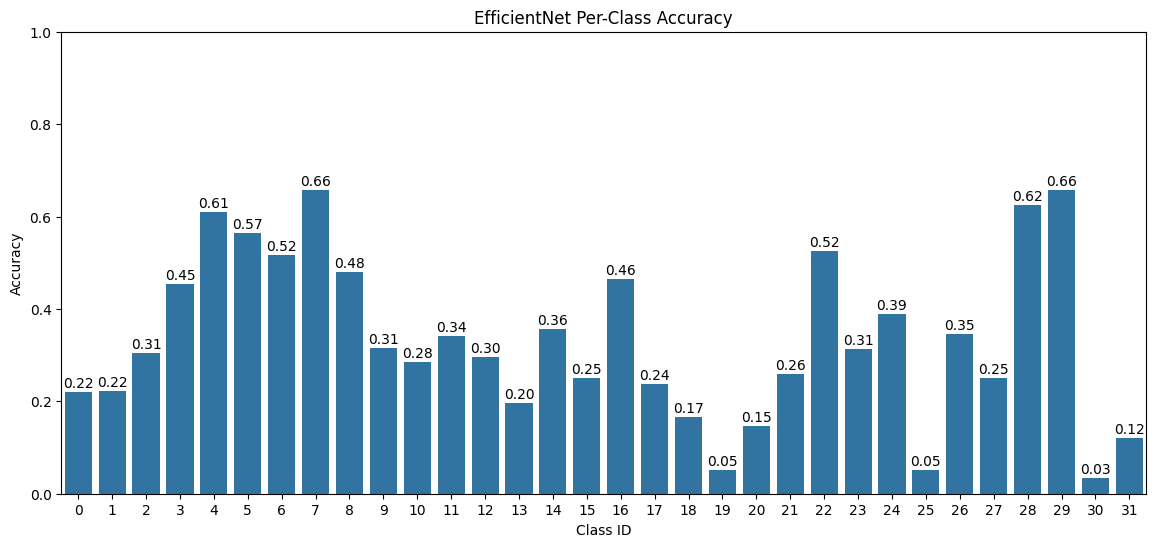

In [21]:
# Cell 9: Per-Class Accuracy Bar Plot
eff_per_class_acc = [eff_report[str(i)]['recall'] for i in range(num_classes)]

classes = list(range(num_classes))

plt.figure(figsize=(14, 6))
sns.barplot(x=classes, y=eff_per_class_acc)
plt.title('EfficientNet Per-Class Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Class ID')
plt.ylim(0, 1)
for i, acc in enumerate(eff_per_class_acc):
    plt.text(i, acc + 0.01, f'{acc:.2f}', ha='center')
plt.show()

<Figure size 1200x1000 with 0 Axes>

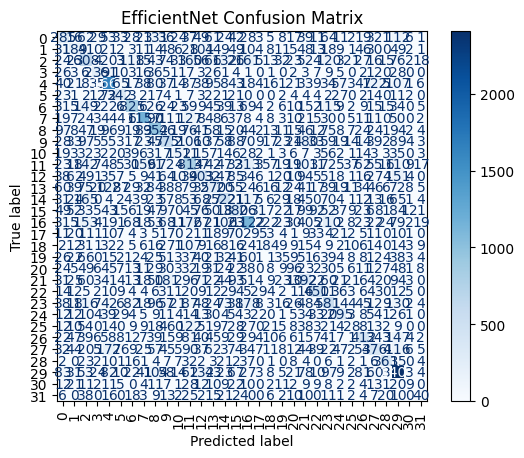

In [22]:
# Cell 10: Confusion Matrix
eff_cm = confusion_matrix(true_labels, eff_preds)

plt.figure(figsize=(12, 10))
disp_eff = ConfusionMatrixDisplay(confusion_matrix=eff_cm, display_labels=classes)
disp_eff.plot(xticks_rotation='vertical', cmap='Blues')
plt.title('EfficientNet Confusion Matrix')
plt.show()

EfficientNet Avg Precision: 0.3522, Recall: 0.3346, F1: 0.3400


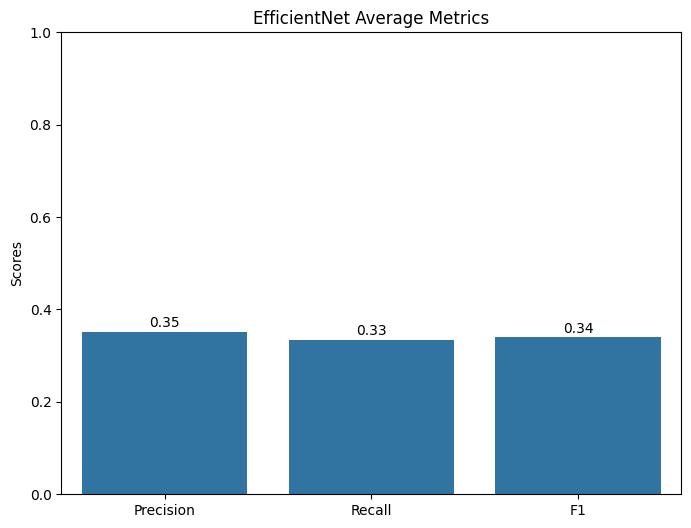

In [23]:
# Cell 11: Average Precision, Recall, F1
eff_precision = [eff_report[str(i)]['precision'] for i in range(num_classes)]
eff_recall = [eff_report[str(i)]['recall'] for i in range(num_classes)]
eff_f1 = [eff_report[str(i)]['f1-score'] for i in range(num_classes)]

eff_avg_prec = np.mean(eff_precision)
eff_avg_rec = np.mean(eff_recall)
eff_avg_f1 = np.mean(eff_f1)

print(f"EfficientNet Avg Precision: {eff_avg_prec:.4f}, Recall: {eff_avg_rec:.4f}, F1: {eff_avg_f1:.4f}")

# Bar plot for average metrics
metrics = ['Precision', 'Recall', 'F1']
eff_avgs = [eff_avg_prec, eff_avg_rec, eff_avg_f1]

plt.figure(figsize=(8, 6))
sns.barplot(x=metrics, y=eff_avgs)
plt.title('EfficientNet Average Metrics')
plt.ylabel('Scores')
plt.ylim(0, 1)
for i, v in enumerate(eff_avgs):
    plt.text(i, v + 0.01, f'{v:.2f}', ha='center')
plt.show()

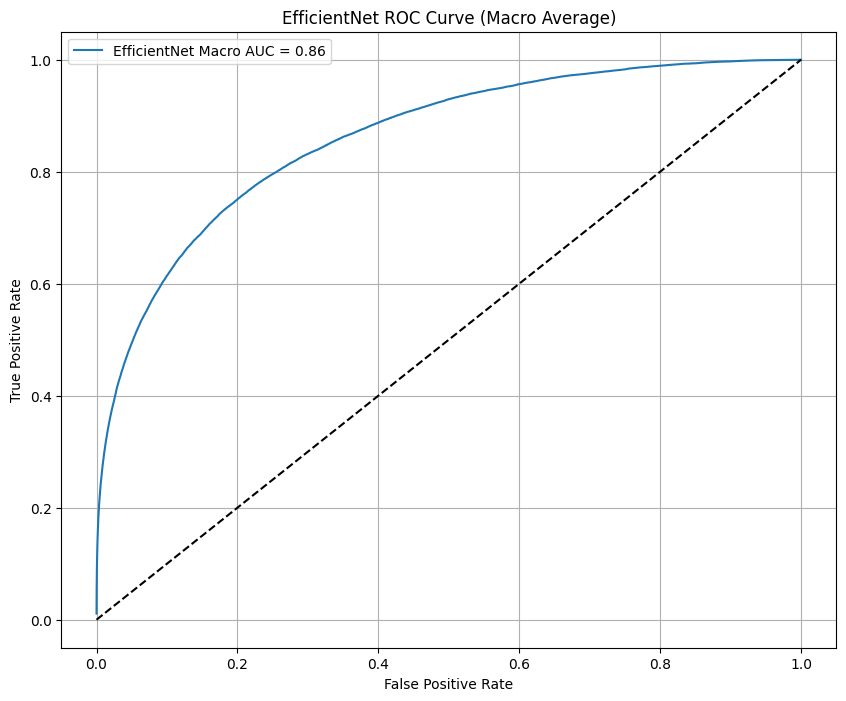

In [28]:
# Cell 12: ROC Curve (Macro Average)
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Binarize labels
bin_labels = label_binarize(true_labels, classes=range(num_classes))

# EfficientNet ROC
fpr_eff = dict()
tpr_eff = dict()
roc_auc_eff = dict()
for i in range(num_classes):
    fpr_eff[i], tpr_eff[i], _ = roc_curve(bin_labels[:, i], eff_probs[:, i])
    roc_auc_eff[i] = auc(fpr_eff[i], tpr_eff[i])

# Macro average using np.interp
all_fpr_eff = np.unique(np.concatenate([fpr_eff[i] for i in range(num_classes)]))
mean_tpr_eff = np.zeros_like(all_fpr_eff)
for i in range(num_classes):
    mean_tpr_eff += np.interp(all_fpr_eff, fpr_eff[i], tpr_eff[i])  # Fixed: use np.interp
mean_tpr_eff /= num_classes
fpr_eff["macro"] = all_fpr_eff
tpr_eff["macro"] = mean_tpr_eff
roc_auc_eff["macro"] = auc(fpr_eff["macro"], tpr_eff["macro"])

# Plot
plt.figure(figsize=(10, 8))
plt.plot(fpr_eff["macro"], tpr_eff["macro"], label=f'EfficientNet Macro AUC = {roc_auc_eff["macro"]:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('EfficientNet ROC Curve (Macro Average)')
plt.legend()
plt.grid(True)
plt.show()